# Part 3 - Nuclei: segmentation, type and counting (PanNuke)

Finds every cell nucleus in a 256 x 256 tile at 40x, draws its outline, says what type of cell it is and counts them. Pathologists judge a tumour partly by its nuclei (how many, how big, which kind), and "segmentation" and "quantification" are two of the four tasks in the AIRA Matrix JD.

Counting needs **instance segmentation**: not only "is this pixel a nucleus" but "which nucleus is it". Nuclei that touch each other are the hard part.

What is in this notebook:
1. Downloading PanNuke and turning it into simple arrays
2. U-Net with three outputs (nucleus or not, distance to the border, type)
3. Watershed to split touching nuclei, and a trap to watch out for
4. Metrics: Dice, AJI, PQ and the counting error
5. (Optional) counting nuclei inside the tumour regions found in Part 2

Runtime -> Change runtime type -> T4 GPU.

In [1]:
!pip install -q segmentation-models-pytorch openslide-python openslide-bin awscli

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 74.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.2/20.2 MB 87.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 570.5/570.5 kB 48.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


In [2]:
import os
import glob
import json
import time
import random
import warnings
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy import ndimage as ndi
from skimage import morphology
from skimage.color import hed_from_rgb, rgb_from_hed
from skimage.segmentation import find_boundaries, watershed

# scikit-image prints a harmless note when a tile has only one nucleus
warnings.filterwarnings('ignore', message = 'Only one label')

In [3]:
import torch
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import get_linear_schedule_with_warmup

print('torch', torch.__version__, '| smp', smp.__version__)

torch 2.11.0+cu130 | smp 0.5.0


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
save_dir = '/content/drive/MyDrive/pathology_project'
data_dir = '/content/pannuke'
os.makedirs(save_dir, exist_ok = True)
os.makedirs(data_dir, exist_ok = True)
print(os.listdir(save_dir))

[]


In [6]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('Device :', device)

types = ['background', 'neoplastic', 'inflammatory', 'connective', 'dead', 'epithelial']
colors = np.array([[0, 0, 0], [255, 0, 0], [0, 200, 0], [0, 90, 255], [255, 220, 0], [255, 120, 0]])

Device : cuda


# Data Loading

PanNuke has 7,901 tiles of 256 x 256 px at 40x from 19 tissues (breast, colon, lung ...), with about 190k nuclei, each one outlined and given one of 5 types. It comes in 3 folds, each with:
- `images.npy`: (N, 256, 256, 3)
- `masks.npy`: (N, 256, 256, 6), channels 0-4 have the **id of every nucleus** of that type (each nucleus has its own number), channel 5 is the background
- `types.npy`: the tissue of every tile

Every fold is turned into 4 simple arrays:
- `images`: uint8
- `inst`: one id per nucleus, all types together (0 = background)
- `types`: 0 = background, 1-5 = the type
- `dist`: for every nucleus the distance to its border, scaled so the centre is 1. This is what the model learns to split touching nuclei (section "Watershed")

The original files are float64 and big (about 12 GB per fold), so the folds are downloaded, converted and deleted one at a time.

In [7]:
def merge_masks(masks):
    # (256, 256, 6) one channel per type -> one instance map and one type map
    inst = np.zeros(masks.shape[:2], dtype = np.int32)
    typ = np.zeros(masks.shape[:2], dtype = np.uint8)
    next_id = 1
    for c in range(5):
        channel = masks[:, :, c].astype(np.int64)
        for nucleus_id in np.unique(channel):
            if nucleus_id == 0:
                continue
            pixels = (channel == nucleus_id) & (inst == 0)
            inst[pixels] = next_id
            typ[pixels] = c + 1
            next_id += 1
    return inst, typ


def distance_map(inst):
    # for every nucleus: distance to its border divided by the largest one -> 1 in the centre, close to 0 at the edge
    out = np.zeros(inst.shape, dtype = np.float32)
    for k, box in enumerate(ndi.find_objects(inst), start = 1):
        if box is None:
            continue
        box = tuple(slice(max(s.start - 1, 0), s.stop + 1) for s in box)   # 1 px bigger so the border is inside
        nucleus = inst[box] == k
        d = ndi.distance_transform_edt(nucleus)
        if d.max() > 0:
            out[box][nucleus] = (d / d.max())[nucleus]
    return out

In [8]:
def prepare_fold(k, folder):
    images = np.load(glob.glob(folder + '/**/images.npy', recursive = True)[0], mmap_mode = 'r')
    masks = np.load(glob.glob(folder + '/**/masks.npy', recursive = True)[0], mmap_mode = 'r')
    tissue = np.load(glob.glob(folder + '/**/types.npy', recursive = True)[0], allow_pickle = True)
    n = len(images)

    out_dir = f'{data_dir}/fold{k}'
    os.makedirs(out_dir, exist_ok = True)
    out_images = np.lib.format.open_memmap(out_dir + '/images.npy', mode = 'w+', dtype = np.uint8, shape = (n, 256, 256, 3))
    out_inst = np.lib.format.open_memmap(out_dir + '/inst.npy', mode = 'w+', dtype = np.int32, shape = (n, 256, 256))
    out_types = np.lib.format.open_memmap(out_dir + '/types.npy', mode = 'w+', dtype = np.uint8, shape = (n, 256, 256))
    out_dist = np.lib.format.open_memmap(out_dir + '/dist.npy', mode = 'w+', dtype = np.float16, shape = (n, 256, 256))

    for i in tqdm(range(n), leave = False):
        out_images[i] = np.clip(images[i], 0, 255).astype(np.uint8)
        inst, typ = merge_masks(np.array(masks[i]))
        out_inst[i] = inst
        out_types[i] = typ
        out_dist[i] = distance_map(inst)

    for a in [out_images, out_inst, out_types, out_dist]:
        a.flush()
    np.save(out_dir + '/tissue.npy', tissue)
    print('Fold', k, ':', n, 'tiles')

In [9]:
for k in [1, 2, 3]:
    if os.path.exists(f'{data_dir}/fold{k}/dist.npy'):
        print('Fold', k, 'already done')
        continue
    !wget -c -q -O /content/fold_{k}.zip https://warwick.ac.uk/fac/cross_fac/tia/data/pannuke/fold_{k}.zip
    !unzip -q -o /content/fold_{k}.zip -d /content/fold_{k} && rm /content/fold_{k}.zip
    prepare_fold(k, f'/content/fold_{k}')
    !rm -rf /content/fold_{k}

  0%|          | 0/2656 [00:00<?, ?it/s]

Fold 1 : 2656 tiles


  0%|          | 0/2523 [00:00<?, ?it/s]

Fold 2 : 2523 tiles


  0%|          | 0/2722 [00:00<?, ?it/s]

Fold 3 : 2722 tiles


In [10]:
def load_fold(k):
    fold = {}
    for name in ['images', 'inst', 'types', 'dist']:
        fold[name] = np.load(f'{data_dir}/fold{k}/{name}.npy', mmap_mode = 'r')
    fold['tissue'] = np.load(f'{data_dir}/fold{k}/tissue.npy', allow_pickle = True)
    return fold


folds = {k: load_fold(k) for k in [1, 2, 3]}
[folds[k]['images'].shape for k in [1, 2, 3]]

[(2656, 256, 256, 3), (2523, 256, 256, 3), (2722, 256, 256, 3)]

In [11]:
# number of nuclei of every type in each fold
for k in [1, 2, 3]:
    counts = np.zeros(6, dtype = int)
    for i in range(len(folds[k]['inst'])):
        inst = np.array(folds[k]['inst'][i])
        typ = np.array(folds[k]['types'][i])
        for c in range(1, 6):
            counts[c] += len(np.unique(inst[typ == c]))
    print('Fold', k, ':', dict(zip(types[1:], counts[1:].tolist())))

Fold 1 : {'neoplastic': 26201, 'inflammatory': 10820, 'connective': 16388, 'dead': 967, 'epithelial': 8842}
Fold 2 : {'neoplastic': 22731, 'inflammatory': 10631, 'connective': 16756, 'dead': 884, 'epithelial': 8870}
Fold 3 : {'neoplastic': 28471, 'inflammatory': 10825, 'connective': 17441, 'dead': 1057, 'epithelial': 8860}


In [12]:
pd.Series(folds[1]['tissue']).value_counts()

,count
Breast,827
Colon,478
Bile-duct,159
Cervix,155
Esophagus,155
Adrenal_gland,134
Lung,80
Thyroid,80
Pancreatic,78
Prostate,77


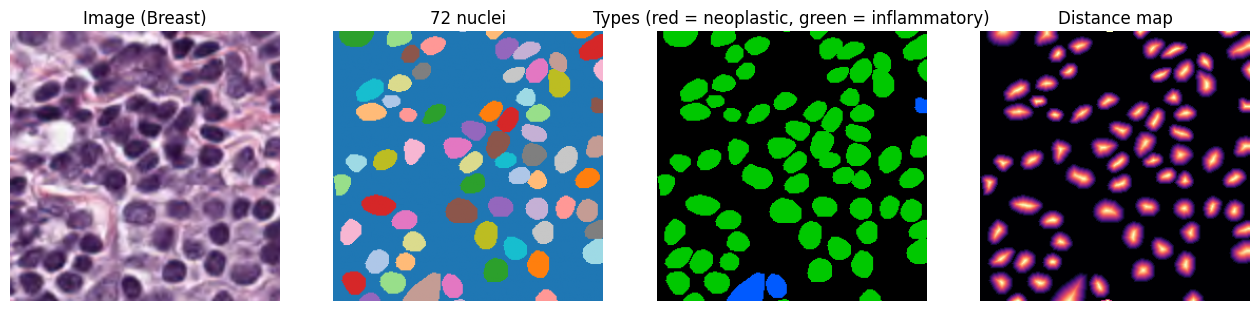

In [13]:
# the tile of fold 1 with the most nuclei (among the first 200)
i = int(np.argmax([len(np.unique(folds[1]['inst'][j])) for j in range(min(200, len(folds[1]['inst'])))]))

fig, axes = plt.subplots(nrows = 1, ncols = 4, figsize = (16,4.5))
axes[0].imshow(folds[1]['images'][i])
axes[0].set_title('Image (' + str(folds[1]['tissue'][i]) + ')')
axes[1].imshow(np.array(folds[1]['inst'][i]) % 20, cmap = 'tab20')
axes[1].set_title(str(len(np.unique(folds[1]['inst'][i])) - 1) + ' nuclei')
axes[2].imshow(colors[np.array(folds[1]['types'][i])])
axes[2].set_title('Types (red = neoplastic, green = inflammatory)')
axes[3].imshow(np.array(folds[1]['dist'][i]).astype(np.float32), cmap = 'magma')
axes[3].set_title('Distance map')
for ax in axes:
    ax.axis('off')
plt.show()

# U-Net

Standard PanNuke split: train on fold 1, pick the best epoch on fold 2, test once on fold 3.

**Augmentation:** the same rotations, flips and HED stain jitter as in Part 1, but every move has to be done the same way on the image **and** on the three target maps, otherwise the outlines don't match the image anymore. There are only about 2,600 training tiles, so this runs fine on the CPU.

In [14]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

In [15]:
encoder = 'resnet34'
batch_size = 16
epochs = 40
lr = 3e-4
weight_decay = 1e-4
warmup_ratio = 0.05
patience = 8
num_workers = 2

In [16]:
# True -> runs everything on a small sample just to check that the pipeline works, False -> full training
debug = False

In [17]:
if debug == True:
    for k in [1, 2, 3]:
        for name in ['images', 'inst', 'types', 'dist', 'tissue']:
            folds[k][name] = folds[k][name][:200]
    epochs = 2

In [18]:
def hed_jitter(image):
    # same idea as in part 1: rgb -> optical density -> stains, change the stains a little, and back
    od = -np.log((image.astype(np.float32) + 1) / 256).reshape(-1, 3)
    hed = od @ hed_from_rgb.astype(np.float32)
    hed = hed * np.random.uniform(0.95, 1.05, 3) + np.random.uniform(-0.05, 0.05, 3)
    od = hed @ rgb_from_hed.astype(np.float32)
    return np.clip(256 * np.exp(-od) - 1, 0, 255).astype(np.uint8).reshape(image.shape)


class NucleiDataset(torch.utils.data.Dataset):
    def __init__(self, fold, augment = False):
        self.fold = fold
        self.augment = augment

    def __len__(self):
        return len(self.fold['images'])

    def __getitem__(self, idx):
        image = np.array(self.fold['images'][idx])
        inst = np.array(self.fold['inst'][idx])
        typ = np.array(self.fold['types'][idx])
        dist = np.array(self.fold['dist'][idx]).astype(np.float32)

        if self.augment == True:
            k = random.randint(0, 3)
            flip = random.random() < 0.5
            maps = []
            for m in [image, inst, typ, dist]:
                m = np.rot90(m, k)                 # the same rotation and flip for all four
                if flip:
                    m = m[:, ::-1]
                maps.append(np.ascontiguousarray(m))
            image, inst, typ, dist = maps
            image = hed_jitter(image)              # colour change only on the image

        item = {
            'image': torch.from_numpy(image).permute(2, 0, 1),
            'nucleus': torch.from_numpy((inst > 0).astype(np.float32)).unsqueeze(0),
            'dist': torch.from_numpy(dist).unsqueeze(0),
            'type': torch.from_numpy(typ.astype(np.int64)),
            'inst': torch.from_numpy(inst.astype(np.int64)),
            'idx': idx
        }
        return item

In [19]:
train_ds = NucleiDataset(folds[1], augment = True)
val_ds = NucleiDataset(folds[2])
test_ds = NucleiDataset(folds[3])

# seed every dataloader worker differently, otherwise they all make the same random augmentations
def seed_worker(worker_id):
    random.seed(torch.initial_seed() % 2**32)
    np.random.seed(torch.initial_seed() % 2**32)

train_loader = DataLoader(train_ds, batch_size = batch_size, shuffle = True, drop_last = True, num_workers = num_workers, worker_init_fn = seed_worker, pin_memory = use_amp)
val_loader = DataLoader(val_ds, batch_size = batch_size, shuffle = False, num_workers = num_workers, pin_memory = use_amp)
test_loader = DataLoader(test_ds, batch_size = batch_size, shuffle = False, num_workers = num_workers, pin_memory = use_amp)

len(train_ds), len(val_ds), len(test_ds)

(2656, 2523, 2722)

In [20]:
batch = next(iter(train_loader))
batch['image'].shape, batch['nucleus'].shape, batch['dist'].shape, batch['type'].shape

(torch.Size([16, 3, 256, 256]),
 torch.Size([16, 1, 256, 256]),
 torch.Size([16, 1, 256, 256]),
 torch.Size([16, 256, 256]))

## Model

**U-Net:** the **encoder** (a ResNet-34 with ImageNet weights) makes the image smaller step by step and learns *what* is there. The **decoder** makes it big again (256 x 256). The **skip connections** give the decoder the detailed early features of the encoder at every size, so the thin borders between nuclei don't get lost. `segmentation_models_pytorch` builds it in one line.

The last layer has 8 channels, so the model gives 3 things for every pixel:

| Channels | What | Loss |
|---|---|---|
| 0 | nucleus or background | BCE + soft Dice (Dice helps because nuclei are a small part of the image) |
| 1 | distance map (1 in the centre, 0 at the border) | MSE, weight 2 |
| 2-7 | type: background + the 5 nucleus types | cross entropy |

In [21]:
model = smp.Unet(encoder_name = encoder, encoder_weights = 'imagenet', in_channels = 3, classes = 2 + len(types))
model = model.to(device)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

In [22]:
sum(p.numel() for p in model.parameters())

24437384

In [23]:
mean = torch.tensor([0.485, 0.456, 0.406], device = device).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device = device).view(1, 3, 1, 1)

def normalize(images):
    return (images.float() / 255 - mean) / std


def dice_loss(logits, target):
    p = torch.sigmoid(logits)
    overlap = (p * target).sum(dim = (1, 2, 3))
    total = p.sum(dim = (1, 2, 3)) + target.sum(dim = (1, 2, 3))
    return 1 - ((2 * overlap + 1) / (total + 1)).mean()


def nuclei_loss(out, batch):
    nucleus_logit = out[:, 0:1].float()
    dist = torch.sigmoid(out[:, 1:2].float())
    type_logits = out[:, 2:].float()
    loss_nucleus = F.binary_cross_entropy_with_logits(nucleus_logit, batch['nucleus']) + dice_loss(nucleus_logit, batch['nucleus'])
    loss_dist = F.mse_loss(dist, batch['dist'])
    loss_type = F.cross_entropy(type_logits, batch['type'])
    return loss_nucleus + 2 * loss_dist + loss_type

In [24]:
# no weight decay on the biases and batch norm weights
optimizer_params = [
    {'params': [p for n, p in model.named_parameters() if p.ndim > 1], 'weight_decay': weight_decay},
    {'params': [p for n, p in model.named_parameters() if p.ndim == 1], 'weight_decay': 0.0}
]
optimizer = torch.optim.AdamW(optimizer_params, lr = lr)

total_steps = len(train_loader) * epochs
warmup_steps = int(warmup_ratio * total_steps)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps = warmup_steps, num_training_steps = total_steps)
scaler = torch.amp.GradScaler('cuda', enabled = use_amp)

print('Total steps :', total_steps, '| Warmup steps :', warmup_steps)

Total steps : 6640 | Warmup steps : 332


In [25]:
def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    for batch in tqdm(loader, leave = False):
        batch = {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch.items()}
        optimizer.zero_grad()
        with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = use_amp):
            out = model(normalize(batch['image']))
        loss = nuclei_loss(out, batch)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += loss.item()
    return total_loss / len(loader)


def evaluate(model, loader):
    # validation loss and dice of the nucleus mask over all pixels
    model.eval()
    total_loss = 0
    overlap = 0
    total = 0
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) if torch.is_tensor(v) else v for k, v in batch.items()}
            with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = use_amp):
                out = model(normalize(batch['image']))
            total_loss += nuclei_loss(out, batch).item()
            pred = out[:, 0:1] > 0
            truth = batch['nucleus'] > 0.5
            overlap += (pred & truth).sum().item()
            total += pred.sum().item() + truth.sum().item()
    return total_loss / len(loader), 2 * overlap / max(total, 1)

## Training

`val loss` can jump around in the first epochs: batch norm's running averages are still settling and in eval mode the model uses them. It calms down after a few epochs. A val Dice that stays near 0 after about 5 epochs would be a real problem.

In [26]:
best_dice = -1
best_state = None
bad_epochs = 0
history = {'train_loss': [], 'val_loss': [], 'val_dice': []}

for epoch in range(epochs):
    start = time.time()
    train_loss = train_one_epoch(model, train_loader)
    val_loss, val_dice = evaluate(model, val_loader)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['val_dice'].append(val_dice)
    print(f'Epoch {epoch + 1}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val dice {val_dice:.4f} | {(time.time() - start) / 60:.1f} min')

    # keep the weights of the best epoch (by validation dice)
    if val_dice > best_dice:
        best_dice = val_dice
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        best_epoch = epoch + 1
        bad_epochs = 0
        torch.save({'state_dict': best_state, 'config': {'encoder': encoder}, 'epoch': best_epoch}, save_dir + '/nuclei_unet.pt')
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print('Early stopping')
            break

print('Best epoch :', best_epoch, '| Best val dice :', round(best_dice, 4))

  0%|          | 0/166 [00:00<?, ?it/s]

Epoch 1/40 | train loss 2.9045 | val loss 1.7743 | val dice 0.7547 | 0.9 min


  0%|          | 0/166 [00:00<?, ?it/s]

Epoch 2/40 | train loss 1.1948 | val loss 0.8295 | val dice 0.8208 | 0.8 min


  0%|          | 0/166 [00:00<?, ?it/s]

...

  0%|          | 0/166 [00:00<?, ?it/s]

Epoch 34/40 | train loss 0.4366 | val loss 0.5149 | val dice 0.8551 | 0.8 min


  0%|          | 0/166 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ae3b5fb0fe0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ae3b5fb0fe0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 35/40 | train loss 0.4327 | val loss 0.5130 | val dice 0.8563 | 1.1 min
Early stopping
Best epoch : 27 | Best val dice : 0.8568


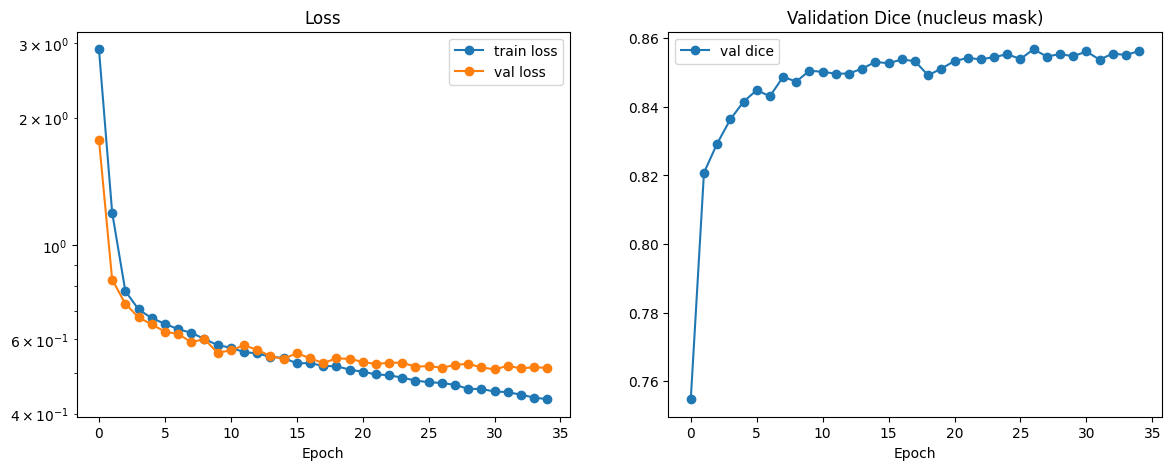

In [27]:
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (14,5))
axes[0].plot(history['train_loss'], marker = 'o', label = 'train loss')
axes[0].plot(history['val_loss'], marker = 'o', label = 'val loss')
axes[0].set_yscale('log')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history['val_dice'], marker = 'o', label = 'val dice')
axes[1].set_title('Validation Dice (nucleus mask)')
axes[1].set_xlabel('Epoch')
axes[1].legend()
plt.savefig(save_dir + '/nuclei_training_curves.png', dpi = 120)
plt.show()

In [28]:
model.load_state_dict(best_state)
model.eval()
print('Loaded the weights of epoch', best_epoch)

Loaded the weights of epoch 27


# Watershed

The nucleus mask alone sticks touching nuclei together into one blob. The distance map is what splits them:
1. **nucleus pixels** = mask probability above 0.5
2. **markers** = the cores of the nuclei, where the (slightly smoothed) distance is above `marker_thr`. Between two touching nuclei the distance goes down, so each one gets its own core
3. **watershed** fills outwards from every marker over `-distance` and stops where two fills meet. Those lines are the borders between the nuclei (inside it's a priority queue: the lowest pixels are filled first, like Dijkstra on the pixels)
4. every nucleus gets the type most of its pixels have

First on two toy disks that touch.

In [29]:
def remove_small(mask, size):
    try:
        return morphology.remove_small_objects(mask, max_size = size)
    except TypeError:
        return morphology.remove_small_objects(mask, min_size = size + 1)


def split_nuclei(nucleus_prob, dist, marker_thr = 0.4, smooth = True, min_marker = 4):
    mask = remove_small(nucleus_prob > 0.5, 10)
    if smooth == True:
        dist = ndi.gaussian_filter(dist.astype(np.float32), sigma = 1)
    markers, _ = ndi.label((dist > marker_thr) & mask)
    markers = remove_small(markers, min_marker - 1)              # drop tiny specks
    inst = watershed(-dist, markers, mask = mask)

    # blobs that got no marker keep their own id
    leftovers, n = ndi.label(mask & (inst == 0))
    if n > 0:
        inst = np.where(leftovers > 0, leftovers + inst.max(), inst)
    inst = remove_small(inst, 10)

    # number the nuclei 1, 2, 3 ... again
    ids = np.unique(inst[inst > 0])
    new_ids = np.zeros(inst.max() + 1, dtype = np.int32)
    new_ids[ids] = np.arange(1, len(ids) + 1)
    return new_ids[inst]


def nucleus_types(inst, type_probs):
    # the type of every nucleus = the type most of its pixels have (background left out)
    pixel_type = type_probs[1:].argmax(axis = 0) + 1
    result = {}
    for k, box in enumerate(ndi.find_objects(inst), start = 1):
        if box is not None:
            result[k] = int(np.bincount(pixel_type[box][inst[box] == k]).argmax())
    return result

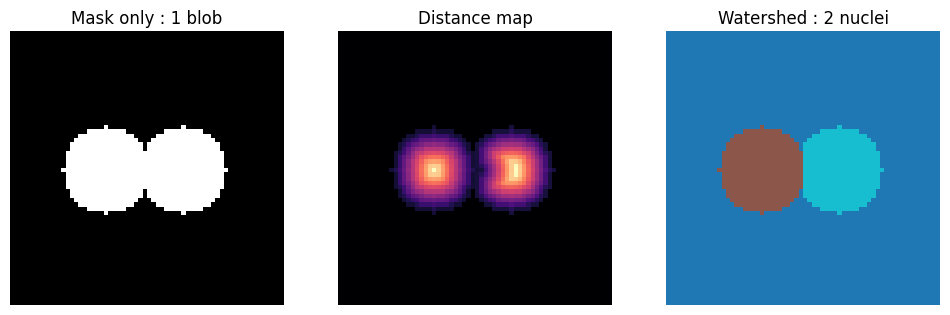

In [30]:
yy, xx = np.mgrid[0:64, 0:64]
toy = np.zeros((64, 64), dtype = np.int32)
toy[(yy - 32) ** 2 + (xx - 22) ** 2 <= 100] = 1
toy[((yy - 32) ** 2 + (xx - 40) ** 2 <= 100) & (toy == 0)] = 2
toy_dist = distance_map(toy)
toy_split = split_nuclei((toy > 0).astype(np.float32), toy_dist)

fig, axes = plt.subplots(nrows = 1, ncols = 3, figsize = (12,4))
axes[0].imshow(toy > 0, cmap = 'gray')
axes[0].set_title('Mask only : ' + str(ndi.label(toy > 0)[1]) + ' blob')
axes[1].imshow(toy_dist, cmap = 'magma')
axes[1].set_title('Distance map')
axes[2].imshow(toy_split, cmap = 'tab10')
axes[2].set_title('Watershed : ' + str(toy_split.max()) + ' nuclei')
for ax in axes:
    ax.axis('off')
plt.show()

**A trap (good for the interview).** The distance map of a trained model never reaches 1 (MSE pulls the peaks down, often to about 0.5 - 0.6), and its top is flat and noisy. Cut that at 0.5 and the core of one nucleus breaks into several specks, so **one nucleus becomes several**. The pixel Dice still looks great but the counts are wrong. That's why the map is smoothed, tiny markers are dropped, and `marker_thr` is chosen on validation. Below it's simulated with 4 nuclei.

In [31]:
four = np.zeros((96, 96), dtype = np.int32)
yy, xx = np.mgrid[0:96, 0:96]
for k, (cy, cx) in enumerate([(20, 20), (20, 60), (60, 30), (70, 75)], start = 1):
    four[((yy - cy) ** 2 + (xx - cx) ** 2 <= 81) & (four == 0)] = k

# what a trained model's distance map looks like: lower peaks and some noise
np.random.seed(5)
noisy_dist = np.clip(distance_map(four) * 0.55 + np.random.normal(0, 0.04, four.shape) * (four > 0), 0, 1)
nucleus_prob = (four > 0).astype(np.float32)

naive = split_nuclei(nucleus_prob, noisy_dist, marker_thr = 0.5, smooth = False, min_marker = 1)
fixed = split_nuclei(nucleus_prob, noisy_dist, marker_thr = 0.4)
print('True nuclei : 4')
print('Cut at 0.5, no smoothing :', naive.max())
print('Smoothed, cut at 0.4, tiny markers dropped :', fixed.max())

True nuclei : 4
Cut at 0.5, no smoothing : 7
Smoothed, cut at 0.4, tiny markers dropped : 4


# Metrics

- **Dice** (pixels): overlap of the predicted and true nucleus masks. It can't see nuclei that are stuck together or split.
- **AJI:** every true nucleus is paired with the predicted one it overlaps most, and the predictions left over are added to the bottom of the fraction. Punishes both sticking and splitting.
- **PQ = DQ x SQ** (the standard PanNuke metric). A prediction **matches** a true nucleus if their IoU is above 0.5 (above 0.5 there can only be one match). **DQ** = TP / (TP + FP/2 + FN/2), an F1 score over nuclei: did we find them? **SQ** = the average IoU of the matches: how well are they outlined? **bPQ** ignores the type, **PQ per type** uses it.
- **Counting error:** the difference between the predicted and the true number of nuclei per tile.

The overlap of *every* true nucleus with *every* predicted one comes from **one `bincount`** of `true_id * (n_pred + 1) + pred_id`: one pass over the pixels instead of a loop over all the pairs.

In [32]:
def overlap_table(truth, pred):
    # number the ids 0..n (0 = background) so they can be used as positions in an array
    truth = np.unique(np.concatenate([[0], truth.ravel()]), return_inverse = True)[1][1:]
    pred = np.unique(np.concatenate([[0], pred.ravel()]), return_inverse = True)[1][1:]
    n_truth = truth.max()
    n_pred = pred.max()
    table = np.bincount(truth * (n_pred + 1) + pred, minlength = (n_truth + 1) * (n_pred + 1)).reshape(n_truth + 1, n_pred + 1)
    inter = table[1:, 1:].astype(float)
    area_truth = table.sum(axis = 1)[1:]
    area_pred = table.sum(axis = 0)[1:]
    union = area_truth[:, None] + area_pred[None, :] - inter
    return inter, union, area_truth, area_pred


def pq(truth, pred):
    if truth.max() == 0 and pred.max() == 0:
        return {'pq': 1.0, 'dq': 1.0, 'sq': 1.0}
    inter, union, area_truth, area_pred = overlap_table(truth, pred)
    iou = inter / np.maximum(union, 1)
    tp = (iou > 0.5).sum()
    fp = len(area_pred) - tp
    fn = len(area_truth) - tp
    sq = iou[iou > 0.5].mean() if tp > 0 else 0.0
    dq = tp / (tp + 0.5 * fp + 0.5 * fn)
    return {'pq': dq * sq, 'dq': dq, 'sq': sq}


def aji(truth, pred):
    if truth.max() == 0:
        return float(pred.max() == 0)
    if pred.max() == 0:
        return 0.0
    inter, union, area_truth, area_pred = overlap_table(truth, pred)
    iou = inter / np.maximum(union, 1)
    total_inter = 0
    total_union = 0
    used = np.zeros(len(area_pred), dtype = bool)
    for g in range(len(area_truth)):
        j = iou[g].argmax()
        if iou[g, j] > 0:
            total_inter += inter[g, j]
            total_union += union[g, j]
            used[j] = True
        else:
            total_union += area_truth[g]
    total_union += area_pred[~used].sum()       # predictions that matched nothing
    return total_inter / total_union


def dice(a, b):
    return 2 * (a & b).sum() / max(a.sum() + b.sum(), 1)

In [33]:
# checks: a perfect prediction gives 1, and the two demos above
print('Perfect :', pq(toy, toy)['pq'], aji(toy, toy))
print('Toy disks PQ :', round(pq(toy, toy_split)['pq'], 3))
print('Trap demo PQ, naive vs fixed :', round(pq(four, naive)['pq'], 3), 'vs', round(pq(four, fixed)['pq'], 3))

Perfect : 1.0 1.0
Toy disks PQ : 0.997
Trap demo PQ, naive vs fixed : 0.57 vs 1.0


# Evaluation

`marker_thr` is chosen on fold 2 (validation), the one with the best bPQ is kept, and fold 3 is tested **once** with it. Choosing it on fold 3 would be tuning on test.

In [34]:
def predict_maps(images):
    # (n, 3, 256, 256) uint8 -> nucleus probability, distance and type probabilities as numpy
    with torch.no_grad():
        with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = use_amp):
            out = model(normalize(images.to(device))).float()
    nucleus_prob = torch.sigmoid(out[:, 0]).cpu().numpy()
    dist = torch.sigmoid(out[:, 1]).cpu().numpy()
    type_probs = torch.softmax(out[:, 2:], dim = 1).cpu().numpy()
    return nucleus_prob, dist, type_probs


def type_map(inst, nucleus_type):
    out = np.zeros(inst.shape, dtype = np.uint8)
    for k, t in nucleus_type.items():
        out[inst == k] = t
    return out


def evaluate_fold(loader, fold, marker_thr):
    rows = []
    examples = []
    for batch in tqdm(loader, leave = False):
        nucleus_prob, dist, type_probs = predict_maps(batch['image'])
        for j in range(len(nucleus_prob)):
            truth = batch['inst'][j].numpy()
            truth_type = batch['type'][j].numpy()
            pred = split_nuclei(nucleus_prob[j], dist[j], marker_thr)
            pred_type = type_map(pred, nucleus_types(pred, type_probs[j]))

            row = {'tissue': fold['tissue'][int(batch['idx'][j])], 'dice': dice(pred > 0, truth > 0), 'aji': aji(truth, pred)}
            scores = pq(truth, pred)
            row['bpq'], row['dq'], row['sq'] = scores['pq'], scores['dq'], scores['sq']
            row['true_count'] = len(np.unique(truth)) - 1
            row['pred_count'] = len(np.unique(pred)) - 1
            for c in range(1, 6):
                truth_c = np.where(truth_type == c, truth, 0)
                pred_c = np.where(pred_type == c, pred, 0)
                row['true_' + types[c]] = len(np.unique(truth_c)) - 1
                row['pred_' + types[c]] = len(np.unique(pred_c)) - 1
                if truth_c.any() or pred_c.any():
                    row['pq_' + types[c]] = pq(truth_c, pred_c)['pq']
            rows.append(row)

            if len(examples) < 4 and row['true_count'] >= 15:
                examples.append((batch['image'][j].permute(1, 2, 0).numpy(), truth, truth_type, pred, pred_type, row))
    return pd.DataFrame(rows), examples

In [35]:
for t in [0.3, 0.4, 0.5, 0.6]:
    val_scores, _ = evaluate_fold(val_loader, folds[2], t)
    count_error = (val_scores['true_count'] - val_scores['pred_count']).abs().mean()
    print(f'marker_thr {t} | bPQ {val_scores.bpq.mean():.4f} | AJI {val_scores.aji.mean():.4f} | counting error {count_error:.2f} nuclei per tile')

  0%|          | 0/158 [00:00<?, ?it/s]

marker_thr 0.3 | bPQ 0.6370 | AJI 0.6689 | counting error 3.00 nuclei per tile


  0%|          | 0/158 [00:00<?, ?it/s]

marker_thr 0.4 | bPQ 0.6413 | AJI 0.6749 | counting error 2.94 nuclei per tile


  0%|          | 0/158 [00:00<?, ?it/s]

marker_thr 0.5 | bPQ 0.6401 | AJI 0.6717 | counting error 2.99 nuclei per tile


  0%|          | 0/158 [00:00<?, ?it/s]

marker_thr 0.6 | bPQ 0.6282 | AJI 0.6534 | counting error 3.32 nuclei per tile


In [36]:
marker_thr = 0.4       # <- the best bPQ on fold 2 above
test_scores, examples = evaluate_fold(test_loader, folds[3], marker_thr)
test_scores.head()

  0%|          | 0/171 [00:00<?, ?it/s]

,tissue,dice,aji,bpq,dq,sq,true_count,pred_count,true_neoplastic,pred_neoplastic,...,pq_inflammatory,true_connective,pred_connective,pq_connective,true_dead,pred_dead,true_epithelial,pred_epithelial,pq_epithelial,pq_dead
0,Breast,0.851249,0.666855,0.571475,0.769231,0.742917,13,13,10,12,...,0.739018,2,0,0.000000,0,0,0,0,NaN,NaN
1,Breast,0.857519,0.750577,0.623901,0.777778,0.802159,8,10,4,8,...,NaN,4,2,0.493672,0,0,0,0,NaN,NaN
2,Breast,0.782393,0.527824,0.524125,0.720000,0.727951,11,14,3,10,...,0.000000,7,4,0.393656,0,0,0,0,NaN,NaN
3,Breast,0.756375,0.608202,0.669513,0.857143,0.781099,11,10,10,10,...,NaN,1,0,0.000000,0,0,0,0,NaN,NaN
4,Breast,0.894180,0.808613,0.728578,0.857143,0.850008,11,10,9,8,...,0.000000,1,2,0.539741,0,0,0,0,NaN,NaN


In [37]:
per_tissue = test_scores.groupby('tissue')[['dice', 'aji', 'bpq']].mean().sort_values('bpq')
count_error = (test_scores['true_count'] - test_scores['pred_count']).abs().mean()

print('Dice :', round(test_scores['dice'].mean(), 4))
print('AJI :', round(test_scores['aji'].mean(), 4))
print('bPQ (mean over tissues) :', round(per_tissue['bpq'].mean(), 4))
print('DQ :', round(test_scores['dq'].mean(), 4), '| SQ :', round(test_scores['sq'].mean(), 4))
print('Counting error :', round(count_error, 2), 'nuclei per tile | correlation :', round(np.corrcoef(test_scores['true_count'], test_scores['pred_count'])[0, 1], 3))

Dice : 0.8023
AJI : 0.6788
bPQ (mean over tissues) : 0.6585
DQ : 0.7796 | SQ : 0.8171
Counting error : 3.06 nuclei per tile | correlation : 0.964


In [38]:
# pq and counting error for every type
type_table = []
for t in types[1:]:
    type_table.append({'type': t,
                       'pq': test_scores['pq_' + t].mean() if 'pq_' + t in test_scores else np.nan,
                       'counting error': (test_scores['true_' + t] - test_scores['pred_' + t]).abs().mean(),
                       'true nuclei per tile': test_scores['true_' + t].mean()})
type_table = pd.DataFrame(type_table)
print('mPQ (mean over types) :', round(type_table['pq'].mean(), 4))
type_table.round(3)

mPQ (mean over types) : 0.3158


,type,pq,counting error,true nuclei per tile
0,neoplastic,0.473,3.048,10.460
1,inflammatory,0.348,1.419,3.977
2,connective,0.344,2.512,6.407
3,dead,0.000,0.388,0.388
4,epithelial,0.414,1.082,3.255


In [39]:
# the weakest tissues
per_tissue.round(3).head(10)

,dice,aji,bpq
tissue,,,
Colon,0.721,0.629,0.594
Skin,0.792,0.617,0.602
Lung,0.833,0.656,0.615
Uterus,0.848,0.652,0.624
Pancreatic,0.851,0.657,0.626
Ovarian,0.858,0.666,0.640
Esophagus,0.852,0.679,0.645
Breast,0.835,0.686,0.650
Kidney,0.782,0.674,0.660


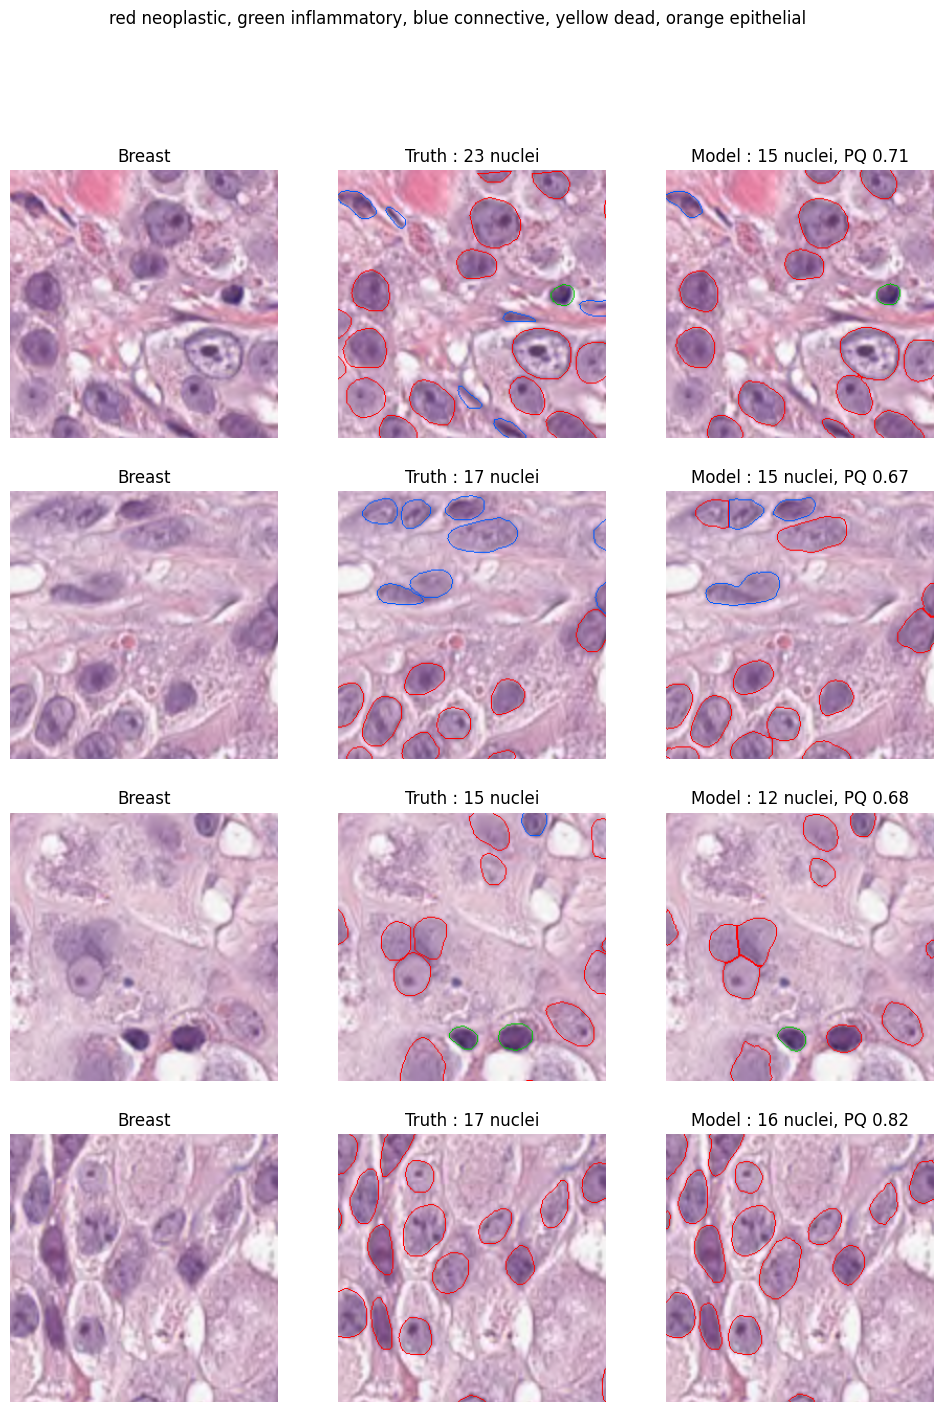

In [40]:
def draw_outlines(image, inst, typ):
    out = image.copy()
    border = find_boundaries(inst, mode = 'inner')
    out[border] = colors[typ[border]]
    return out


fig, axes = plt.subplots(nrows = len(examples), ncols = 3, figsize = (12, 4 * len(examples)), squeeze = False)
for r, (image, truth, truth_type, pred, pred_type, row) in enumerate(examples):
    axes[r, 0].imshow(image)
    axes[r, 0].set_title(str(row['tissue']))
    axes[r, 1].imshow(draw_outlines(image, truth, truth_type))
    axes[r, 1].set_title('Truth : ' + str(row['true_count']) + ' nuclei')
    axes[r, 2].imshow(draw_outlines(image, pred, pred_type))
    axes[r, 2].set_title(f"Model : {row['pred_count']} nuclei, PQ {row['bpq']:.2f}")
    for ax in axes[r]:
        ax.axis('off')
plt.suptitle('red neoplastic, green inflammatory, blue connective, yellow dead, orange epithelial')
plt.savefig(save_dir + '/nuclei_examples.png', dpi = 110)
plt.show()

# Save the model

In [41]:
info = {
    'best_epoch': best_epoch,
    'val_dice': float(best_dice),
    'marker_thr': marker_thr,
    'test_dice': float(test_scores['dice'].mean()),
    'test_aji': float(test_scores['aji'].mean()),
    'test_bpq': float(per_tissue['bpq'].mean()),
    'test_mpq': float(type_table['pq'].mean()),
    'counting_error': float(count_error)
}
with open(save_dir + '/nuclei_results.json', 'w') as f:
    json.dump(info, f, indent = 2)
info

{'best_epoch': 27,
 'val_dice': 0.8568214422353136,
 'marker_thr': 0.4,
 'test_dice': 0.8023011976306152,
 'test_aji': 0.6787796974395202,
 'test_bpq': 0.658497656242339,
 'test_mpq': 0.3157968205171645,
 'counting_error': 3.0635562086700956}

In [42]:
# for the streamlit app: fp16 weights (about 49 MB instead of 98, under github's 100 MB limit) and a few test tiles
app_dir = save_dir + '/app_artifacts'
os.makedirs(app_dir + '/examples/pannuke', exist_ok = True)

half_state = {k: v.half() if v.is_floating_point() else v for k, v in best_state.items()}
torch.save({'state_dict': half_state, 'config': {'encoder': encoder, 'marker_thr': marker_thr}}, app_dir + '/nuclei_best.pt')

for j in range(6):
    Image.fromarray(np.array(folds[3]['images'][j])).save(f"{app_dir}/examples/pannuke/{folds[3]['tissue'][j]}_{j}.png")
os.listdir(app_dir)

['examples', 'nuclei_best.pt']

Next: copy the `app_artifacts` folder from Drive into `app/artifacts/` and run the Streamlit app, then fill in RESULTS.md.

Note for the interview: HoVer-Net gets bPQ about 0.66 and mPQ about 0.46 on PanNuke. A U-Net with one distance map trained for 40 epochs on one fold will most likely be below that. The reasons: HoVer-Net uses two direction maps, trains longer and uses the official evaluation script.